# Customer Churn Prediction with Logistic Regression

## Project objective
Train **one algorithm only: Logistic Regression** to predict whether a telecom customer will churn (`Yes`) or stay (`No`).

## Model output
After training, the complete preprocessing + Logistic Regression pipeline is saved to:

`models/customer_churn_model.pkl`

The `models/` directory is created automatically if it does not exist.

## Dataset
Use the IBM Telco Customer Churn CSV named `WA_Fn-UseC_-Telco-Customer-Churn.csv`. Place it in the same directory as this notebook, or change `DATA_PATH` below.

**Target column:** `Churn`

This is a learning project. Predictions are estimates and should not be treated as guarantees.

## 1. Install dependencies

In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

## 2. Import libraries

In [31]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the dataset

In [32]:
DATA_PATH = Path("Customer-Churn.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Download the IBM Telco Customer Churn CSV, put it beside this notebook, "
        "or update DATA_PATH to the correct path."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Inspect the dataset

In [33]:
print("Columns:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nSummary statistics:")
display(df.describe(include="all").T)

print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Onli

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nMissing values:


,missing_count
customerID,0
DeviceProtection,0
TotalCharges,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0


## 5. Clean the dataset

In the common Telco churn CSV, `TotalCharges` may be stored as text. Convert it to numeric; blank values become missing values and will be handled by the preprocessing pipeline.

`customerID` is an identifier, so it is excluded from model features.

In [34]:
df = df.copy()

if "Churn" not in df.columns:
    raise ValueError("Target column 'Churn' was not found in the CSV.")

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.drop_duplicates().dropna(subset=["Churn"]).copy()

print("Dataset shape after basic cleaning:", df.shape)
display(df["Churn"].value_counts(dropna=False).to_frame("count"))

Dataset shape after basic cleaning: (7043, 21)


/var/folders/kb/5k24n_390rb3g3xwdn5nfft80000gn/T/ipykernel_5875/2844001771.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")


,count
Churn,
No,5174
Yes,1869


## 6. Exploratory data analysis

/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/seaborn/_base.py:1447: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  self.plot_data[axis] = cat_data
/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/seaborn/categorical.py

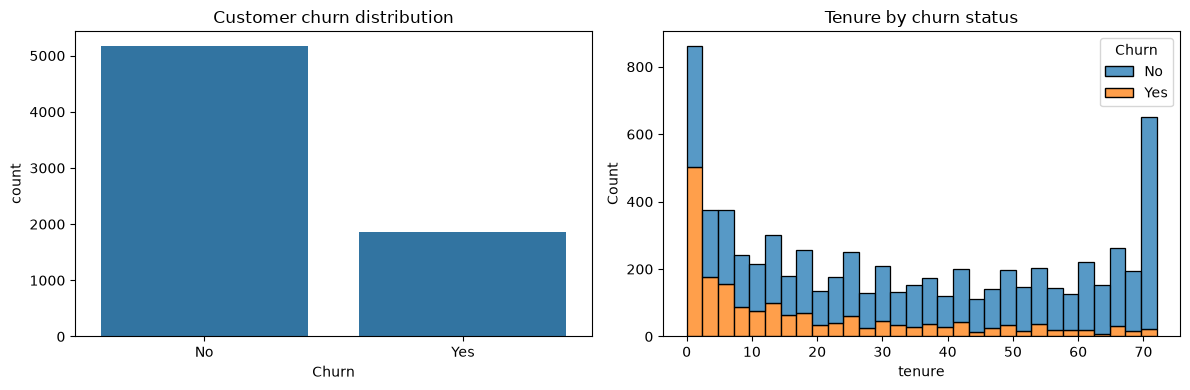

/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/seaborn/_base.py:1447: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  self.plot_data[axis] = cat_data
/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/seaborn/categorical.py

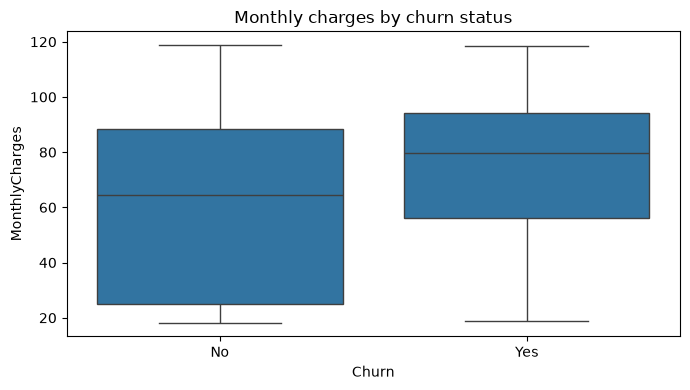

Churn rate (%):


,percentage
Churn,
No,73.46
Yes,26.54


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Customer churn distribution")

if "tenure" in df.columns:
    sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack", ax=axes[1])
    axes[1].set_title("Tenure by churn status")
else:
    axes[1].axis("off")

plt.tight_layout()
plt.show()

if "MonthlyCharges" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("Monthly charges by churn status")
    plt.tight_layout()
    plt.show()

print("Churn rate (%):")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

## 7. Separate features and target

- `X` contains customer attributes used for prediction.
- `y` contains the churn label, encoded as `No = 0` and `Yes = 1`.
- The customer ID is dropped because it should not be used as a predictive feature.

In [36]:
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("The Churn column must contain only 'Yes' and 'No' values.")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())

X shape: (7043, 19)
y shape: (7043,)
Features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


## 8. Split training and testing data

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training churn rate:", round(y_train.mean(), 3))
print("Testing churn rate:", round(y_test.mean(), 3))

Training rows: 5634
Testing rows: 1409
Training churn rate: 0.265
Testing churn rate: 0.265


## 9. Preprocess features

Logistic Regression requires numeric input. This pipeline:
- fills missing numeric values with the median
- scales numeric features
- fills missing categorical values with the most frequent value
- one-hot encodes categorical features

All preprocessing is fitted on training data only. Keeping preprocessing in the pipeline also makes the saved model easier to use from FastAPI.

In [38]:
# 1. Separate columns
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

# 2. Prepare numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Prepare categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 5. Display the columns
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 10. Train Logistic Regression (the only algorithm)

In [39]:
model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

# The pipeline includes preprocessing and the Logistic Regression estimator.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model),
])

pipeline.fit(X_train, y_train)
print("Logistic Regression training complete.")

Logistic Regression training complete.


/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


## 11. Evaluate the model

,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.738,0.504,0.783,0.614,0.841


Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



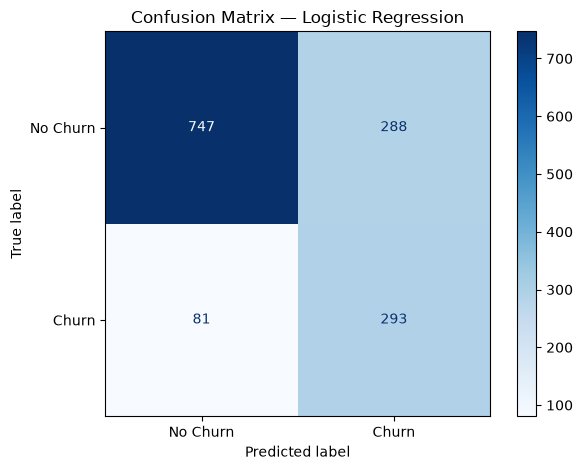

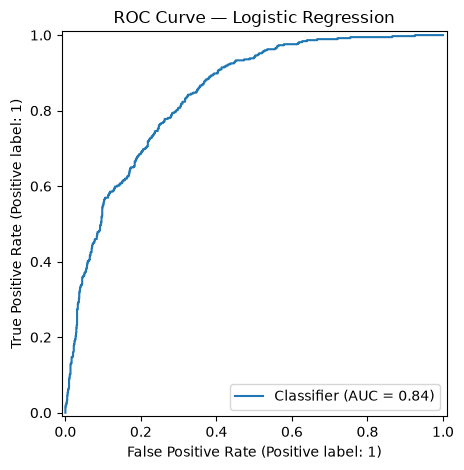

In [40]:
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}])

display(metrics.round(3))

print("Classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
)
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve — Logistic Regression")
plt.tight_layout()
plt.show()

## 12. Inspect Logistic Regression coefficients

,coefficient
numeric__tenure,-1.123589
categorical__Contract_Two year,-0.781257
categorical__InternetService_Fiber optic,0.705336
numeric__MonthlyCharges,-0.663581
categorical__Contract_Month-to-month,0.663399
categorical__InternetService_DSL,-0.621009
numeric__TotalCharges,0.457211
categorical__StreamingMovies_Yes,0.274978
categorical__OnlineSecurity_No internet service,-0.274568
categorical__InternetService_No,-0.274568


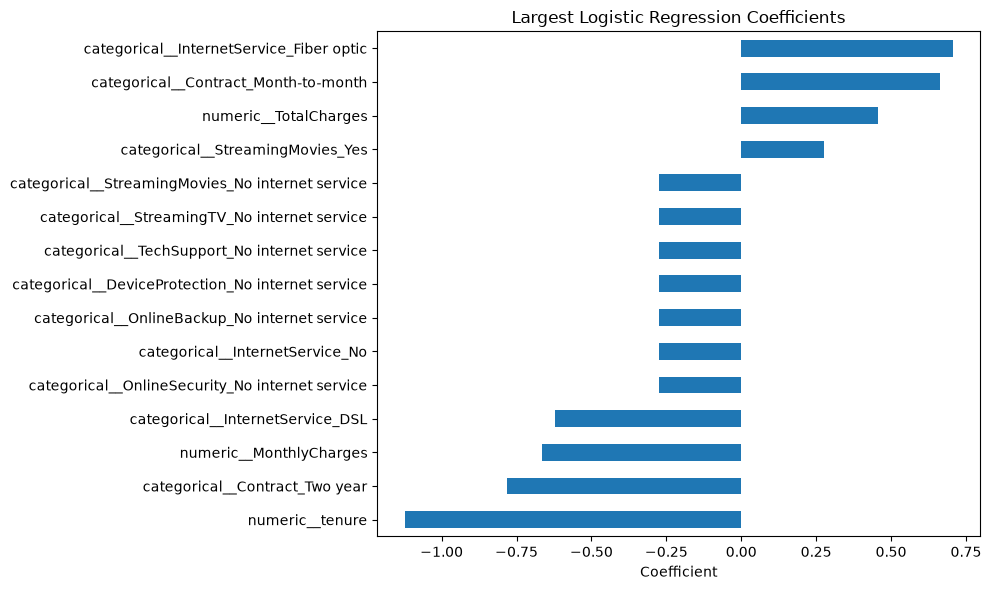

Positive coefficients generally increase the model's log-odds of churn; negative coefficients decrease them.
Interpret coefficients cautiously because categorical features are one-hot encoded.


In [41]:
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(
    pipeline.named_steps["model"].coef_[0],
    index=feature_names,
).sort_values(key=np.abs, ascending=False)

display(coefficients.head(20).to_frame("coefficient"))

plt.figure(figsize=(10, 6))
coefficients.head(15).sort_values().plot(kind="barh")
plt.title("Largest Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

print("Positive coefficients generally increase the model's log-odds of churn; negative coefficients decrease them.")
print("Interpret coefficients cautiously because categorical features are one-hot encoded.")

## 13. Predict one customer

This example predicts the first row in the test set. Replace it with a customer record that has the same input columns as `X` to test another case.

In [42]:
sample_customer = X_test.iloc[[0]]

prediction = int(pipeline.predict(sample_customer)[0])
churn_probability = float(pipeline.predict_proba(sample_customer)[0, 1])

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print(f"Estimated churn probability: {churn_probability:.1%}")
display(sample_customer)

Prediction: No Churn
Estimated churn probability: 11.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


## 14. Save the model inside the `models/` folder

The directory is created automatically. The saved file contains both the preprocessing steps and the trained Logistic Regression model.

In [43]:
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "customer_churn_model.pkl"
joblib.dump(pipeline, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH.resolve()}")

Model saved to: /Users/aftab/Desktop/ML/Projects/Customer_Churn_Prediction/models/customer_churn_model.pkl


## 15. Reload and verify the saved model

In [ ]:
loaded_model = joblib.load(MODEL_PATH)

loaded_prediction = loaded_model.predict(sample_customer)
original_prediction = pipeline.predict(sample_customer)

assert np.array_equal(loaded_prediction, original_prediction)
print("Model loaded successfully.")
print("Prediction after loading:", "Churn" if loaded_prediction[0] == 1 else "No Churn")

## 16. Project summary and next step

This notebook uses **Logistic Regression only** and saves the complete fitted pipeline to `models/customer_churn_model.pkl`.

Next, load the model in a FastAPI application using:

```python
import joblib
from pathlib import Path

MODEL_PATH = Path("models/customer_churn_model.pkl")
model = joblib.load(MODEL_PATH)
```

Run the API from the project root so the relative `models/` path resolves correctly.

### Checklist
- [ ] Dataset CSV is in the expected location
- [ ] All cells run successfully
- [ ] Evaluation metrics are reviewed
- [ ] `models/customer_churn_model.pkl` exists
- [ ] The saved model reloads and returns a prediction

**Note:** This is a learning baseline. Validate model performance and data quality before using it for real customer decisions.